'\nkNN + Bayesian Optimization (Optuna, TPE)\n - Prints the hyperparameter pool being explored\n - Tunes on 3-fold CV (fast), reports 10-fold CV accuracy & classification report\n - 75:25 train/test split, evaluates on test\n - Confusion matrix (counts + normalized), ROC (per-class & micro), PR curves (per-class & micro)\n - Reports TPR at fixed FPRs (1% and 5%) per class & micro\n - Saves best model as timestamped .pkl in best_model_trained_after_parameter_tuning/\n'

In [2]:
import warnings
warnings.filterwarnings("ignore")

import os
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    classification_report, roc_curve, auc, RocCurveDisplay,
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, average_precision_score
)
from sklearn.utils.validation import check_is_fitted

import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

import joblib

In [3]:
# =========================
# CONFIG
# =========================
RANDOM_STATE = 42
TUNE_CV_FOLDS = 10        
REPORT_CV_FOLDS = 10     
N_TRIALS = 60            
SCORING = "f1_macro"     
TEST_SIZE = 0.25

In [4]:
# =========================
# DATA LOADING (EDIT THIS)
# =========================
CSV_PATH = r"/mnt/c/Users/Ishara/Documents/MPhil/Dataset/Final dataset/without timing/full sim results.csv"
TARGET_COL = "isUnderAttack"

df = pd.read_csv(CSV_PATH)
feature_cols = [c for c in df.columns if c != TARGET_COL]
X = df[feature_cols].values
y_raw = df[TARGET_COL].values

# Encode labels if not already ints
le = LabelEncoder()
y = le.fit_transform(y_raw)
classes = np.unique(y)
class_names = [str(c) for c in le.classes_]
n_classes = len(classes)

print(f"[INFO] Data: X={X.shape}, y={y.shape}, classes={list(class_names)}")


[INFO] Data: X=(58025, 10), y=(58025,), classes=['0', '1', '2', '3']


In [5]:
# =========================
# CV SETTINGS
# =========================
cv_tune = StratifiedKFold(n_splits=TUNE_CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_report = StratifiedKFold(n_splits=REPORT_CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)


In [6]:
# =========================
# HYPERPARAMETER POOL (PRINTED)
# =========================
# We keep this in one place so it's crystal clear what Optuna will explore.
PARAM_POOL = {
    "n_neighbors": "integer in [1, 200]",
    "weights": ["uniform", "distance"],
    "metric": ["minkowski (with p∈{1,2})", "cosine", "chebyshev"],
    "algorithm": {
        "if metric == 'minkowski'": ["auto", "kd_tree", "ball_tree", "brute"],
        "else": "brute"
    }
}
print("\n=== Hyperparameter Pool (Bayesian Optimization Search Space) ===")
for k, v in PARAM_POOL.items():
    print(f"{k}: {v}")



=== Hyperparameter Pool (Bayesian Optimization Search Space) ===
n_neighbors: integer in [1, 200]
weights: ['uniform', 'distance']
metric: ['minkowski (with p∈{1,2})', 'cosine', 'chebyshev']
algorithm: {"if metric == 'minkowski'": ['auto', 'kd_tree', 'ball_tree', 'brute'], 'else': 'brute'}


In [7]:
# =========================
# Pipeline factory
# =========================
def make_pipeline(params):
    n_neighbors = params["n_neighbors"]
    weights = params["weights"]
    metric = params["metric"]
    p = params.get("p", 2)
    algorithm = params.get("algorithm", "brute")

    knn = KNeighborsClassifier(
        n_neighbors=n_neighbors,
        weights=weights,
        metric=metric if metric != "minkowski" else "minkowski",
        p=p,
        algorithm=algorithm,
        n_jobs=-1
    )
    return Pipeline([("scaler", StandardScaler()), ("knn", knn)])


In [8]:
# =========================
# Optuna objective
# =========================
def objective(trial: optuna.Trial) -> float:
    n_neighbors = trial.suggest_int("n_neighbors", 1, 200)
    weights = trial.suggest_categorical("weights", ["uniform", "distance"])
    metric = trial.suggest_categorical("metric", ["minkowski", "cosine", "chebyshev"])

    if metric == "minkowski":
        p = trial.suggest_int("p", 1, 2)  # Manhattan (1) or Euclidean (2)
        algorithm = trial.suggest_categorical("algorithm", ["auto", "kd_tree", "ball_tree", "brute"])
    else:
        p = 2
        algorithm = "brute"

    params = dict(n_neighbors=n_neighbors, weights=weights, metric=metric, p=p, algorithm=algorithm)
    pipe = make_pipeline(params)
    scores = cross_val_score(pipe, X, y, cv=cv_tune, scoring=SCORING, n_jobs=4)
    return float(np.mean(scores))

study = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=RANDOM_STATE, n_startup_trials=15),
    pruner=MedianPruner(n_startup_trials=15)
)
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)

print("\n=== Best Trial (tuning: {}-fold, scoring: {}) ===".format(TUNE_CV_FOLDS, SCORING))
print(f"Mean {SCORING}: {study.best_trial.value:.6f}")
for k, v in study.best_trial.params.items():
    print(f"  {k}: {v}")

best_params = study.best_trial.params
best_pipe = make_pipeline(best_params)


[I 2025-10-16 17:50:55,262] A new study created in memory with name: no-name-ddd22ee3-8b17-4d12-b1d6-7ea7bb5f160c
[I 2025-10-16 17:50:56,997] Trial 0 finished with value: 0.937165212446148 and parameters: {'n_neighbors': 75, 'weights': 'uniform', 'metric': 'minkowski', 'p': 1, 'algorithm': 'auto'}. Best is trial 0 with value: 0.937165212446148.
[I 2025-10-16 17:50:59,906] Trial 1 finished with value: 0.9025380700145339 and parameters: {'n_neighbors': 194, 'weights': 'uniform', 'metric': 'chebyshev'}. Best is trial 0 with value: 0.937165212446148.
[I 2025-10-16 17:51:01,006] Trial 2 finished with value: 0.9296070764619759 and parameters: {'n_neighbors': 105, 'weights': 'uniform', 'metric': 'minkowski', 'p': 1, 'algorithm': 'kd_tree'}. Best is trial 0 with value: 0.937165212446148.
[I 2025-10-16 17:51:04,651] Trial 3 finished with value: 0.9393875707288007 and parameters: {'n_neighbors': 119, 'weights': 'distance', 'metric': 'chebyshev'}. Best is trial 3 with value: 0.9393875707288007.
[


=== Best Trial (tuning: 10-fold, scoring: f1_macro) ===
Mean f1_macro: 0.976717
  n_neighbors: 5
  weights: distance
  metric: cosine


In [9]:
# =========================
# Helper: TPR at fixed FPR
# =========================
def tpr_at_fixed_fpr(fpr, tpr, target_fpr: float) -> float:
    """Return the maximum TPR where FPR <= target_fpr. If all FPR > target, return 0."""
    fpr = np.asarray(fpr)
    tpr = np.asarray(tpr)
    mask = fpr <= target_fpr
    if not np.any(mask):
        return 0.0
    return float(np.max(tpr[mask]))

In [10]:
# =========================
# 10-fold CV (Out-of-fold predictions)
# =========================
y_pred_cv = cross_val_predict(best_pipe, X, y, cv=cv_report, n_jobs=1)

print("\n=== Classification Report ({}-fold CV, out-of-fold) ===".format(REPORT_CV_FOLDS))
print(classification_report(y, y_pred_cv, target_names=class_names, digits=4))

cv_accuracy = accuracy_score(y, y_pred_cv)
print(f"\n=== Cross-Validated Accuracy ({REPORT_CV_FOLDS}-fold) ===")
print(f"Accuracy: {cv_accuracy:.4f}")


=== Classification Report (10-fold CV, out-of-fold) ===
              precision    recall  f1-score   support

           0     0.9799    0.9858    0.9828     25773
           1     0.9709    0.9725    0.9717     12981
           2     0.9638    0.9502    0.9569     12959
           3     0.9948    0.9960    0.9954      6312

    accuracy                         0.9760     58025
   macro avg     0.9774    0.9761    0.9767     58025
weighted avg     0.9759    0.9760    0.9759     58025


=== Cross-Validated Accuracy (10-fold) ===
Accuracy: 0.9760


In [11]:
# =========================
# 75:25 TRAIN/TEST SPLIT → TRAIN BEST MODEL
# =========================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
best_pipe.fit(X_train, y_train)

# Test predictions
y_pred_test = best_pipe.predict(X_test)

print("\n=== Classification Report (Hold-out Test Set 25%) ===")
print(classification_report(y_test, y_pred_test, target_names=class_names, digits=4))

test_accuracy = accuracy_score(y_test, y_pred_test)
print(f"Test Set Accuracy: {test_accuracy:.4f}")


=== Classification Report (Hold-out Test Set 25%) ===
              precision    recall  f1-score   support

           0     0.9793    0.9820    0.9806      6444
           1     0.9671    0.9680    0.9675      3245
           2     0.9588    0.9488    0.9538      3240
           3     0.9906    0.9987    0.9946      1578

    accuracy                         0.9733     14507
   macro avg     0.9739    0.9744    0.9741     14507
weighted avg     0.9732    0.9733    0.9732     14507

Test Set Accuracy: 0.9733


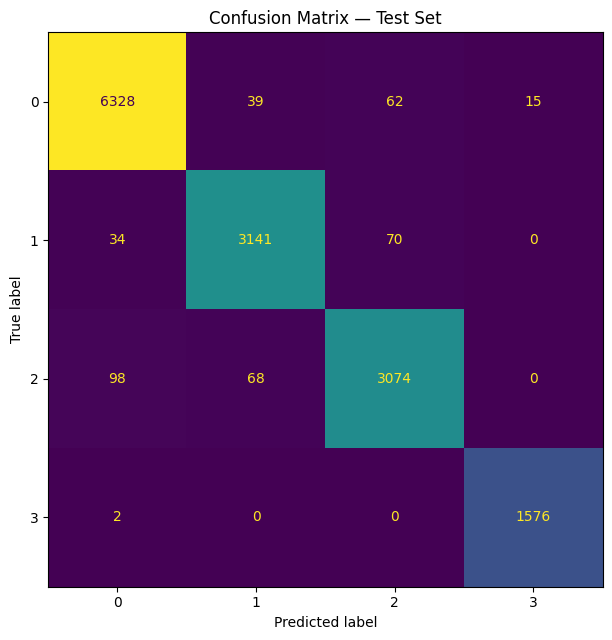

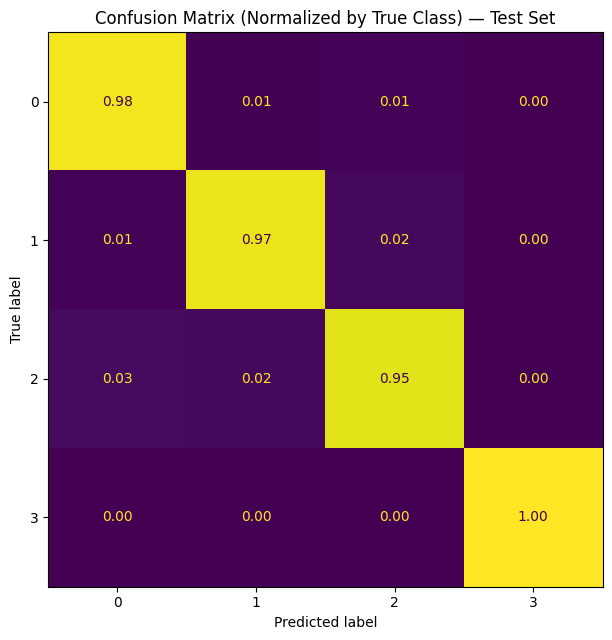

In [12]:
# =========================
# Confusion Matrices (Test)
# =========================
cm = confusion_matrix(y_test, y_pred_test, labels=classes)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, values_format="d", colorbar=False)
plt.title("Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()

cm_norm = confusion_matrix(y_test, y_pred_test, labels=classes, normalize="true")
fig, ax = plt.subplots(figsize=(7.5, 6.5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=class_names)
disp.plot(ax=ax, values_format=".2f", colorbar=False)
plt.title("Confusion Matrix (Normalized by True Class) — Test Set")
plt.tight_layout()
plt.show()

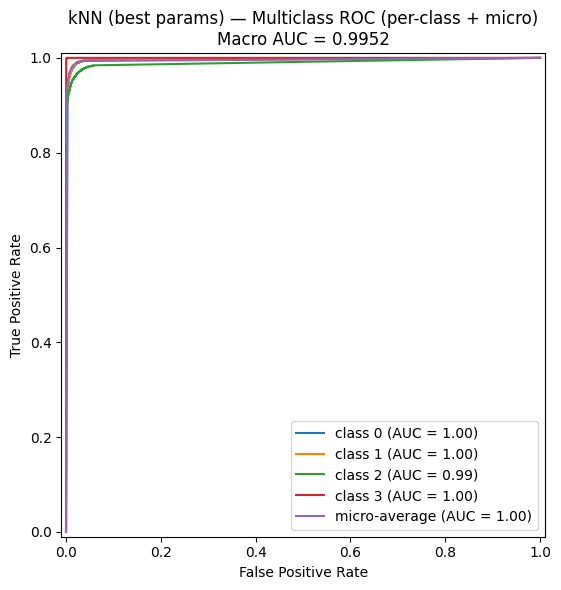


=== AUC Summary (Test) ===
0: AUC = 0.9955
1: AUC = 0.9957
2: AUC = 0.9899
3: AUC = 0.9998
Micro-average AUC = 0.9954
Macro-average AUC = 0.9952

=== TPR at fixed FPR (Test) ===
  FPR≤1%:  |  0 TPR=0.9705  |  1 TPR=0.9692  |  2 TPR=0.9417  |  3 TPR=1.0000  |  micro TPR=0.9761
  FPR≤5%:  |  0 TPR=0.9957  |  1 TPR=0.9948  |  2 TPR=0.9821  |  3 TPR=1.0000  |  micro TPR=0.9934


In [13]:
# =========================
# ROC (Test) — per-class + micro
# =========================
try:
    check_is_fitted(best_pipe)
    y_score = best_pipe.predict_proba(X_test)             # (n_samples, n_classes)
    y_test_bin = label_binarize(y_test, classes=classes)  # (n_samples, n_classes)

    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # micro-average
    fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])
    roc_auc["macro"] = float(np.mean([roc_auc[i] for i in range(n_classes)]))

    plt.figure(figsize=(8, 6))
    for i, cname in enumerate(class_names):
        RocCurveDisplay(fpr=fpr[i], tpr=tpr[i], roc_auc=roc_auc[i],
                        estimator_name=f"class {cname}").plot(ax=plt.gca())
    RocCurveDisplay(fpr=fpr["micro"], tpr=tpr["micro"], roc_auc=roc_auc["micro"],
                    estimator_name="micro-average").plot(ax=plt.gca())
    plt.title("kNN (best params) — Multiclass ROC (per-class + micro)\nMacro AUC = {:.4f}".format(roc_auc["macro"]))
    plt.tight_layout()
    plt.show()

    print("\n=== AUC Summary (Test) ===")
    for i, cname in enumerate(class_names):
        print(f"{cname}: AUC = {roc_auc[i]:.4f}")
    print(f"Micro-average AUC = {roc_auc['micro']:.4f}")
    print(f"Macro-average AUC = {roc_auc['macro']:.4f}")

    # TPR at FPR = 1% and 5% (per-class + micro)
    targets = [0.01, 0.05]
    print("\n=== TPR at fixed FPR (Test) ===")
    for tgt in targets:
        line = [f"FPR≤{int(tgt*100)}%:"]
        for i, cname in enumerate(class_names):
            tpr_fixed = tpr_at_fixed_fpr(fpr[i], tpr[i], tgt)
            line.append(f"{cname} TPR={tpr_fixed:.4f}")
        tpr_micro = tpr_at_fixed_fpr(fpr['micro'], tpr['micro'], tgt)
        line.append(f"micro TPR={tpr_micro:.4f}")
        print("  " + "  |  ".join(line))

except Exception as e:
    print(f"[WARN] Could not compute ROC metrics: {e}")

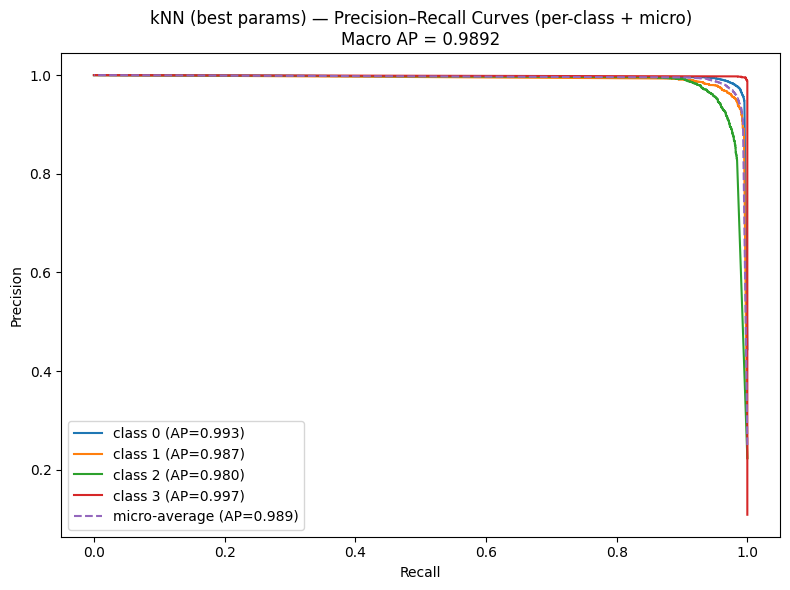


=== Average Precision (AP) Summary (Test) ===
0: AP = 0.9927
1: AP = 0.9870
2: AP = 0.9797
3: AP = 0.9974
Micro-average AP = 0.9891
Macro-average AP = 0.9892


In [14]:
# =========================
# Precision–Recall (Test) — per-class + micro
# =========================
try:
    y_score = best_pipe.predict_proba(X_test)
    y_test_bin = label_binarize(y_test, classes=classes)

    prec, rec, ap = {}, {}, {}
    for i in range(n_classes):
        prec[i], rec[i], _ = precision_recall_curve(y_test_bin[:, i], y_score[:, i])
        ap[i] = average_precision_score(y_test_bin[:, i], y_score[:, i])

    # micro-average
    prec["micro"], rec["micro"], _ = precision_recall_curve(y_test_bin.ravel(), y_score.ravel())
    ap["micro"] = average_precision_score(y_test_bin, y_score, average="micro")
    ap["macro"] = float(np.mean([ap[i] for i in range(n_classes)]))

    plt.figure(figsize=(8, 6))
    for i, cname in enumerate(class_names):
        plt.plot(rec[i], prec[i], label=f"class {cname} (AP={ap[i]:.3f})")
    plt.plot(rec["micro"], prec["micro"], linestyle="--", label=f"micro-average (AP={ap['micro']:.3f})")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("kNN (best params) — Precision–Recall Curves (per-class + micro)\nMacro AP = {:.4f}".format(ap["macro"]))
    plt.legend(loc="lower left")
    plt.tight_layout()
    plt.show()

    print("\n=== Average Precision (AP) Summary (Test) ===")
    for i, cname in enumerate(class_names):
        print(f"{cname}: AP = {ap[i]:.4f}")
    print(f"Micro-average AP = {ap['micro']:.4f}")
    print(f"Macro-average AP = {ap['macro']:.4f}")

except Exception as e:
    print(f"[WARN] Could not compute Precision–Recall metrics: {e}")

In [15]:
# =========================
# SAVE TRAINED BEST PIPELINE AS .PKL (timestamped in folder)
# =========================
save_dir = Path("best_model_trained_after_parameter_tuning")
save_dir.mkdir(parents=True, exist_ok=True)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
model_path = save_dir / f"knn_best_pipeline_{timestamp}.pkl"
joblib.dump(best_pipe, str(model_path))
print(f"\n✅ Model saved at: {model_path.resolve()}")


✅ Model saved at: /home/ubuntu1/projects/MPhilCodes/best_model_trained_after_parameter_tuning/knn_best_pipeline_20251016_180509.pkl
